# Pronóstico del valor del suelo en Bogotá

¿Cuánto costará el m² de terreno en los próximos años, y en qué manzanas subirá
más que en el resto de la ciudad?

El insumo es el **valor de referencia de Catastro** (`V_REF`, COP/m² de terreno
por manzana) para los años **2017 a 2026**: diez observaciones anuales de unas
40 mil manzanas. Diez puntos por serie son pocos para los métodos clásicos de
series de tiempo, pero 40 mil series en paralelo son muchas para un modelo
transversal. Ese desbalance define todo el diseño de este notebook.

## La descomposición que organiza el trabajo

El crecimiento del precio de una manzana se parte en dos sumandos: lo que sube
la ciudad entera (la *deriva*) y lo que esa manzana le gana o le pierde a la
ciudad (el término *relativo*). Son dos problemas distintos, con datos distintos
y modelos distintos, y conviene no mezclarlos:

| | Qué es | Cuántos datos hay | Con qué se ataca |
|---|---|---|---|
| **Deriva** | la inflación del suelo urbano | **una** serie de 10 puntos | series de tiempo |
| **Relativo** | qué zonas se despegan | 40 mil filas × 10 años | aprendizaje supervisado |

Un modelo único que prediga el precio en pesos mezcla ambas cosas y termina
aprendiendo la deriva del período de entrenamiento, que es justo la parte que no
se repite. La **Parte A** pronostica la deriva, la **Parte B** pronostica el
término relativo, la **Parte C** los vuelve a juntar.

## Qué se compara y con qué se mide

- **Parte A**: caminata aleatoria, deriva histórica, deriva reciente, tendencia
  lineal sobre el logaritmo, Holt (suavizamiento exponencial con tendencia) y
  ARIMA.
- **Parte B**: línea base, momentum, reversión a la media, Ridge, ElasticNet,
  árbol de decisión, Random Forest, Extra Trees, Gradient Boosting por
  histogramas, KNN espacial y un ensamble.
- **Sección 5**: una sección entera dedicada a las métricas, porque en este
  problema se contradicen entre sí y elegir mal la métrica cambia el ganador.

> **Advertencia sobre `V_REF`.** No es un precio de transacción: es un valor
> administrativo que Catastro actualiza **por zonas y por turnos**. Eso deja
> huellas que se ven más adelante —un año congelado, crecimientos que se
> alternan— y que conviene tener presentes antes de creerle a cualquier
> pronóstico.

**Requisito**: haber corrido `notebooks/valor_suelo_pesos_m2.ipynb` al menos una
vez, que es el que deja la caché de Catastro en `data/processed/`. Si falta, la
celda de carga la descarga.

## 0. Preparación

In [1]:
import json
import ssl
import sys
import urllib.parse
import urllib.request
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.base import clone
from sklearn.ensemble import (ExtraTreesRegressor, HistGradientBoostingRegressor,
                              RandomForestRegressor)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import ElasticNetCV, LinearRegression, RidgeCV
from sklearn.neighbors import KNeighborsRegressor, NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore")
%matplotlib inline

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import config as C

print("raiz del proyecto:", ROOT)

raiz del proyecto: C:\Users\Usuario\Proyectos\Catastro_ML


### Parámetros editables

In [2]:
# --- ventana de datos -------------------------------------------------------
ANIO_INI, ANIO_FIN = 2017, 2026   # cobertura del valor de referencia

# --- diseño de la validacion temporal ---------------------------------------
H = 3                 # horizonte en años de cada ejercicio de prediccion
ORIGEN_TRAIN = 2020   # se entrena prediciendo ORIGEN_TRAIN -> ORIGEN_TRAIN + H
ORIGEN_TEST = 2023    # se evalua  prediciendo ORIGEN_TEST  -> ORIGEN_TEST  + H

# --- pronostico hacia adelante ----------------------------------------------
ANIOS_PRONOSTICO = 4          # 2027 ... 2030
INFLACION_ESPERADA = None     # p. ej. 0.045 para leer el pronostico en pesos constantes

# --- modelado ---------------------------------------------------------------
K_VECINOS = 8         # vecinos espaciales para las variables de entorno
SEMILLA = C.SEED
N_BOOTSTRAP = 300     # remuestreos por sector para los intervalos de confianza

GUARDAR_TABLAS = True
GUARDAR_FIGURAS = False

F_VREF = C.PROC_DIR / "catastro_valor_referencia.csv.gz"
F_PRONOSTICO = C.PROC_DIR / "pronostico_manzanas.csv.gz"
BASE_ARCGIS = "https://serviciosgis.catastrobogota.gov.co/arcgis/rest/services"
PAGINA = 2000

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 96, "savefig.dpi": 130, "savefig.bbox": "tight",
                     "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold"})
AZUL, VERDE, NARANJA, ROJO, AMARILLO, GRIS = "#264653", "#2a9d8f", "#f4a261", "#e76f51", "#e9c46a", "#9aa5ab"
CMAP_VALOR = "RdYlBu_r"
ASPECTO = 1 / np.cos(np.radians(4.65))

rng = np.random.default_rng(SEMILLA)

def guardar_fig(fig, archivo):
    if GUARDAR_FIGURAS:
        fig.savefig(C.FIG_DIR / archivo, facecolor="white")

def guardar_tabla(tabla, archivo, **kw):
    if GUARDAR_TABLAS:
        tabla.to_csv(C.TAB_DIR / archivo, **kw)

def formato_mapa(ax, titulo=None):
    ax.set_xlim(*C.URB_LON); ax.set_ylim(*C.URB_LAT)
    ax.set_aspect(ASPECTO); ax.set_xlabel("longitud"); ax.grid(alpha=.25)
    if titulo:
        ax.set_title(titulo)

def pesos(x, pos=None):
    return "%.1f M" % (x / 1e6) if x >= 1e6 else "%.0f k" % (x / 1e3)

def pct(x):
    "Pasa un crecimiento anual en log10 a porcentaje anual."
    return 100 * (10 ** x - 1)

print("horizonte %d años | entrena %d->%d | evalua %d->%d | pronostica %d-%d"
      % (H, ORIGEN_TRAIN, ORIGEN_TRAIN + H, ORIGEN_TEST, ORIGEN_TEST + H,
         ANIO_FIN + 1, ANIO_FIN + ANIOS_PRONOSTICO))

horizonte 3 años | entrena 2020->2023 | evalua 2023->2026 | pronostica 2027-2030


## 1. El panel: una fila por manzana, una columna por año

Se arma la matriz de precios y se trabaja en **logaritmo base 10**. Es la
transformación natural aquí: el precio del suelo va de 30 mil a 30 millones de
COP/m², y lo que interesa son los cambios **porcentuales**, que en logaritmos
son simples diferencias.

In [3]:
def cargar_vref():
    "Lee la cache que deja el notebook de pesos; si no existe, la descarga."
    if F_VREF.exists():
        print("valores: desde cache (%s)" % F_VREF.name)
        return pd.read_csv(F_VREF, dtype={"MANCODIGO": str})
    print("no hay cache: descargando de Catastro (~4 min)")
    ctx = ssl.create_default_context(); ctx.check_hostname = False; ctx.verify_mode = ssl.CERT_NONE
    filas, off = [], 0
    while True:
        p = {"f": "json", "returnGeometry": "false", "where": "1=1",
             "outFields": "MANCODIGO,V_REF,ANO", "orderByFields": "OBJECTID",
             "resultOffset": off, "resultRecordCount": PAGINA}
        url = "%s/catastro/valorreferencia/MapServer/0/query?%s" % (BASE_ARCGIS, urllib.parse.urlencode(p))
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=120, context=ctx) as r:
            lote = [f["attributes"] for f in
                    json.loads(r.read().decode("utf-8", "replace")).get("features", [])]
        if not lote:
            break
        filas.extend(lote); off += len(lote)
        print("\r   %6d" % len(filas), end="", flush=True)
        if len(lote) < PAGINA:
            break
    d = pd.DataFrame(filas); d.to_csv(F_VREF, index=False); print()
    return d

vref = cargar_vref()
vref["anio"] = pd.to_datetime(vref["ANO"], unit="ms").dt.year
vref = vref.rename(columns={"MANCODIGO": "manzana", "V_REF": "cop_m2"})[["manzana", "anio", "cop_m2"]]

# un precio de 0 no es un precio: son manzanas sin valor asignado ese año
n_cero = int((vref["cop_m2"] <= 0).sum())
vref = vref[vref["cop_m2"] > 0]
# la capa trae manzanas repetidas dentro de un mismo año -> se consolidan con la mediana
vref = vref.groupby(["manzana", "anio"], as_index=False)["cop_m2"].median()

ancha = vref.pivot(index="manzana", columns="anio", values="cop_m2")
completas = ancha.dropna()
LOG = np.log10(completas)

print("registros utiles    : %d  (descartados %d con precio 0)" % (len(vref), n_cero))
print("manzanas en la capa : %d" % len(ancha))
print("con serie completa  : %d  (%.0f%%)  <- panel de trabajo"
      % (len(completas), 100 * len(completas) / len(ancha)))
completas.head(3)

valores: desde cache (catastro_valor_referencia.csv.gz)


registros utiles    : 421896  (descartados 1111 con precio 0)
manzanas en la capa : 43692
con serie completa  : 40610  (93%)  <- panel de trabajo


anio,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
manzana,,,,,,,,,,
001101001,650000.0,720000.0,870000.0,920000.0,1000000.0,1000000.0,1200000.0,1150000.0,1240000.0,1680000.0
001101002,650000.0,720000.0,870000.0,920000.0,1000000.0,1000000.0,1100000.0,1150000.0,1240000.0,1530000.0
001101003,650000.0,720000.0,870000.0,920000.0,1000000.0,1000000.0,1100000.0,1150000.0,1240000.0,1530000.0


### La serie de la ciudad, y una anomalía que hay que mirar de frente

In [4]:
ciudad = completas.median()
drift = LOG.median().diff().dropna()          # deriva anual en log10

resumen_anual = pd.DataFrame({
    "mediana_ciudad": ciudad.round(0),
    "deriva_log10": drift.round(4),
    "crecimiento_pct": drift.map(pct).round(1),
    "dispersion_entre_manzanas": LOG.diff(axis=1).std().round(4),
    "pct_sin_cambio": (100 * (completas.diff(axis=1) == 0).mean()).round(1),
})
guardar_tabla(resumen_anual, "t30_serie_anual_ciudad.csv")

congelados = [a for a in resumen_anual.index if resumen_anual.loc[a, "pct_sin_cambio"] > 80]
print("crecimiento anual de la ciudad: mediana %.1f%% | minimo %.1f%% | maximo %.1f%%"
      % (resumen_anual["crecimiento_pct"].median(),
         resumen_anual["crecimiento_pct"].min(), resumen_anual["crecimiento_pct"].max()))
if congelados:
    print("AÑOS CONGELADOS (mas del 80%% de manzanas sin cambio): %s"
          % ", ".join(str(a) for a in congelados))
resumen_anual

crecimiento anual de la ciudad: mediana 8.6% | minimo 0.0% | maximo 16.7%
AÑOS CONGELADOS (mas del 80% de manzanas sin cambio): 2022


,mediana_ciudad,deriva_log10,crecimiento_pct,dispersion_entre_manzanas,pct_sin_cambio
anio,,,,,
2017,1200000.0,NaN,NaN,NaN,0.0
2018,1400000.0,0.0669,16.7,0.0629,6.2
2019,1550000.0,0.0442,10.7,0.0840,10.5
2020,1800000.0,0.0649,16.1,0.0899,5.7
2021,1950000.0,0.0348,8.3,0.1087,4.2
2022,1950000.0,0.0000,0.0,0.0000,100.0
2023,2100000.0,0.0322,7.7,0.0705,10.2
2024,2210000.0,0.0222,5.2,0.0614,8.4
2025,2400000.0,0.0358,8.6,0.0377,2.7


Hay un año en que **casi ninguna manzana se movió**: Catastro no actualizó el
valor de referencia. No es un dato faltante —el valor existe— pero tampoco es
información de mercado. Se deja en el panel, porque el pronóstico tiene que
convivir con esa realidad administrativa, pero queda señalado en los gráficos y
explica buena parte de lo que se ve en la sección siguiente.

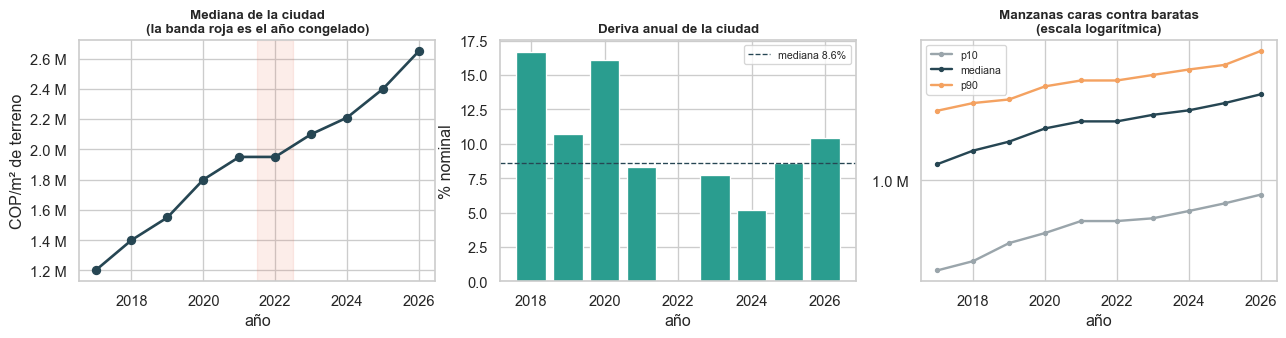

razon p90/p10: 6.1 en 2017  ->  5.1 en 2026


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.6))

ax[0].plot(ciudad.index, ciudad.values, "o-", color=AZUL, lw=2)
for a in congelados:
    ax[0].axvspan(a - .5, a + .5, color=ROJO, alpha=.12)
ax[0].yaxis.set_major_formatter(mticker.FuncFormatter(pesos))
ax[0].set_title("Mediana de la ciudad\n(la banda roja es el año congelado)")
ax[0].set_ylabel("COP/m² de terreno")

anios_g = list(resumen_anual.index[1:])
ax[1].bar(anios_g, resumen_anual["crecimiento_pct"].iloc[1:],
          color=[ROJO if a in congelados else VERDE for a in anios_g])
ax[1].axhline(resumen_anual["crecimiento_pct"].median(), color=AZUL, ls="--", lw=1,
              label="mediana %.1f%%" % resumen_anual["crecimiento_pct"].median())
ax[1].set_title("Deriva anual de la ciudad")
ax[1].set_ylabel("% nominal"); ax[1].legend(fontsize=8)

for q, col, et in [(.1, GRIS, "p10"), (.5, AZUL, "mediana"), (.9, NARANJA, "p90")]:
    ax[2].plot(completas.columns, completas.quantile(q), "o-", color=col, lw=1.8, ms=3, label=et)
ax[2].set_yscale("log")
ax[2].yaxis.set_major_formatter(mticker.FuncFormatter(pesos))
ax[2].set_title("Manzanas caras contra baratas\n(escala logarítmica)")
ax[2].legend(fontsize=8)

for a in ax:
    a.set_xlabel("año")
fig.tight_layout(); guardar_fig(fig, "pron_fig01_serie_ciudad.png"); plt.show()

razon = completas.quantile(.9) / completas.quantile(.1)
print("razon p90/p10: %.1f en %d  ->  %.1f en %d"
      % (razon.iloc[0], ANIO_INI, razon.iloc[-1], ANIO_FIN))

## 2. ¿Qué parte del crecimiento es predecible?

Antes de ajustar nada conviene saber contra qué se está peleando. Tres
diagnósticos, y cada uno cambia una decisión de diseño.

In [6]:
# --- 1. descomposicion de la varianza: ciudad vs manzana --------------------
mz = pd.read_csv(C.F_DATASET, dtype={"manzana": str, "sector": str})
panel = mz.merge(LOG.reset_index(), on="manzana", how="inner").reset_index(drop=True)
print("manzanas del pipeline con serie completa: %d de %d" % (len(panel), len(mz)))

g_fut = (panel[ORIGEN_TEST + H] - panel[ORIGEN_TEST]) / H
var_total = g_fut.var()
var_entre_sectores = panel.assign(g=g_fut).groupby("sector")["g"].mean().var()

# --- 2. ¿el crecimiento pasado anticipa el futuro? -------------------------
g_pas = (panel[ORIGEN_TEST] - panel[ORIGEN_TEST - H]) / H
rho_momentum = g_pas.corr(g_fut, method="spearman")

# --- 3. ¿lo caro crece menos? (reversion a la media) -----------------------
rho_reversion = panel[ORIGEN_TEST].corr(g_fut, method="spearman")

# --- 4. autocorrelacion de la deriva anual ---------------------------------
G = LOG.diff(axis=1).drop(columns=ANIO_INI)
pares = [(a, a + 1) for a in G.columns[:-1] if a not in congelados and a + 1 not in congelados]
autocorr = pd.Series({"%d->%d" % p: G[p[0]].corr(G[p[1]]) for p in pares}).round(3)

diagnostico = pd.DataFrame({
    "diagnostico": ["varianza del crecimiento que es entre sectores",
                    "momentum: crecimiento pasado vs futuro (Spearman)",
                    "reversion: precio actual vs crecimiento futuro (Spearman)",
                    "autocorrelacion media del crecimiento anual"],
    "valor": [round(100 * var_entre_sectores / var_total, 1), round(rho_momentum, 3),
              round(rho_reversion, 3), round(autocorr.mean(), 3)],
    "unidad": ["%", "correlacion", "correlacion", "correlacion"],
})
guardar_tabla(diagnostico, "t31_diagnostico_predictibilidad.csv", index=False)
print()
print(diagnostico.to_string(index=False))
print()
print("autocorrelacion año a año:"); print(autocorr.to_string())

manzanas del pipeline con serie completa: 37442 de 38748

                                              diagnostico  valor      unidad
           varianza del crecimiento que es entre sectores 93.000           %
        momentum: crecimiento pasado vs futuro (Spearman) -0.085 correlacion
reversion: precio actual vs crecimiento futuro (Spearman) -0.318 correlacion
              autocorrelacion media del crecimiento anual -0.258 correlacion

autocorrelacion año a año:
2018->2019   -0.099
2019->2020   -0.400
2020->2021   -0.270
2023->2024   -0.562
2024->2025   -0.112
2025->2026   -0.105


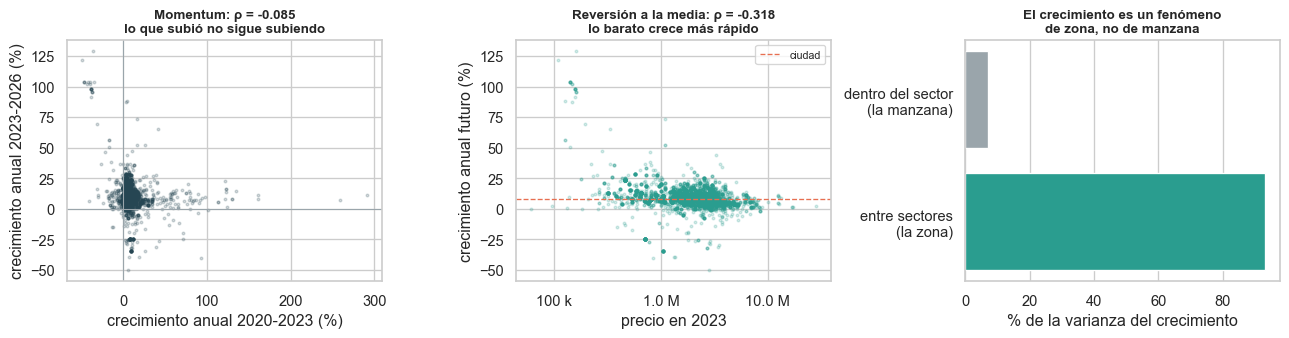

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.6))

muestra = panel.sample(min(6000, len(panel)), random_state=SEMILLA).index
ax[0].scatter(g_pas[muestra].map(pct), g_fut[muestra].map(pct), s=4, alpha=.2, color=AZUL)
ax[0].axhline(0, color=GRIS, lw=.8); ax[0].axvline(0, color=GRIS, lw=.8)
ax[0].set_xlabel("crecimiento anual %d-%d (%%)" % (ORIGEN_TEST - H, ORIGEN_TEST))
ax[0].set_ylabel("crecimiento anual %d-%d (%%)" % (ORIGEN_TEST, ORIGEN_TEST + H))
ax[0].set_title("Momentum: ρ = %.3f\nlo que subió no sigue subiendo" % rho_momentum)

ax[1].scatter(10 ** panel.loc[muestra, ORIGEN_TEST], g_fut[muestra].map(pct),
              s=4, alpha=.2, color=VERDE)
ax[1].set_xscale("log")
ax[1].xaxis.set_major_formatter(mticker.FuncFormatter(pesos))
ax[1].axhline(pct(g_fut.median()), color=ROJO, ls="--", lw=1, label="ciudad")
ax[1].set_xlabel("precio en %d" % ORIGEN_TEST); ax[1].set_ylabel("crecimiento anual futuro (%)")
ax[1].set_title("Reversión a la media: ρ = %.3f\nlo barato crece más rápido" % rho_reversion)
ax[1].legend(fontsize=8)

ax[2].barh(["entre sectores\n(la zona)", "dentro del sector\n(la manzana)"],
           [100 * var_entre_sectores / var_total, 100 * (1 - var_entre_sectores / var_total)],
           color=[VERDE, GRIS])
ax[2].set_xlabel("% de la varianza del crecimiento")
ax[2].set_title("El crecimiento es un fenómeno\nde zona, no de manzana")
ax[2].grid(axis="y", alpha=0)

fig.tight_layout(); guardar_fig(fig, "pron_fig02_predictibilidad.png"); plt.show()

### Lo que dicen estos tres números

1. **El crecimiento es de zona, no de manzana.** Más del 90 % de la varianza
   está *entre* sectores catastrales. Tiene sentido: Catastro revisa por zonas,
   y el mercado del suelo también se mueve por corredores. Consecuencia de
   diseño: las variables de **entorno** (qué hacen los vecinos) deberían pesar
   más que los atributos propios, y los intervalos de confianza hay que
   calcularlos **agrupando por sector**, no manzana a manzana, o saldrán
   absurdamente angostos.

2. **El momentum no existe.** La correlación entre lo que creció una manzana en
   el trienio pasado y lo que crecerá en el siguiente es prácticamente cero, y
   la autocorrelación año a año es **negativa**. Esa es la firma de la
   actualización por turnos: a la zona que revisaron este año le toca esperar.
   Consecuencia: extrapolar la tendencia de cada manzana —que es lo que uno
   haría por defecto— es una mala idea, y hay que demostrarlo con una línea base
   explícita en vez de suponerlo.

3. **Hay reversión a la media, y es la señal transversal más fuerte.** Lo barato
   crece más rápido en términos porcentuales. Consecuencia: el nivel de precio
   actual entra como variable, y el objetivo se define en **relativo a la
   ciudad** para que el modelo no tenga que aprender la deriva de paso.

## 3. El diseño de validación

La tentación es partir las manzanas al azar en entrenamiento y prueba. Aquí eso
mide lo que no es: el objetivo es predecir **el futuro de manzanas conocidas**,
no el presente de manzanas desconocidas. La partición tiene que ser **en el
tiempo**.

| | Se ajusta con | Se evalúa con |
|---|---|---|
| Insumos | historia hasta **2020** | historia hasta **2023** |
| Objetivo | crecimiento **2020 → 2023** | crecimiento **2023 → 2026** |

Los dos bloques contienen las mismas manzanas, y eso está bien: son las que se
quiere pronosticar. Lo que nunca se cruza es el **período**. El precio de 2026
—el que se predice— no entra por ninguna vía al ajuste.

Para ver de qué tamaño es el autoengaño, más adelante se reporta también lo que
habría dicho una partición aleatoria.

### Una regla para las variables

Con un solo período de entrenamiento, cada variable extra es una oportunidad de
memorizar ese período. La regla que se aplica aquí es sencilla y se fija
**antes** de mirar resultados: *no se incluyen combinaciones lineales de
variables que ya están en el modelo*. Por ejemplo, la prima de precio de una
manzana frente a su entorno es la resta de dos variables que ya entran por
separado; parece informativa y no aporta nada nuevo. En el apartado 6.4 se
muestra lo que pasa cuando esa regla se rompe: no es un detalle cosmético.

In [8]:
# vecinos espaciales: se calculan una sola vez sobre la geometria, no sobre el tiempo
XY = np.c_[panel["lon"].values * np.cos(np.radians(4.65)), panel["lat"].values]
_, IDX_VEC = NearestNeighbors(n_neighbors=K_VECINOS + 1).fit(XY).kneighbors(XY)
IDX_VEC = IDX_VEC[:, 1:]          # la primera columna es la manzana misma

FEATURES_BASE = [f for f in C.FEATURES_UBICACION if f in panel.columns] + ["ivs"]

def construir_bloque(t0):
    "Variables observables en t0 y objetivo relativo a t0+H. Nada mira mas alla de t0."
    nivel = panel[t0].values
    g1 = (panel[t0] - panel[t0 - 1]).values            # crecimiento del ultimo año
    g2 = ((panel[t0] - panel[t0 - 2]) / 2).values      # crecimiento anual del ultimo bienio
    X = panel[FEATURES_BASE].copy()
    X["nivel_rel"] = nivel - np.median(nivel)          # que tan cara es frente a la ciudad
    X["g1"] = g1
    X["g2"] = g2
    X["vec_nivel"] = nivel[IDX_VEC].mean(1) - np.median(nivel)
    X["vec_g1"] = g1[IDX_VEC].mean(1)
    X["vec_g2"] = g2[IDX_VEC].mean(1)
    y_abs = (panel[t0 + H] - panel[t0]).values / H      # crecimiento anual en log10
    deriva = np.median(y_abs)
    return X, y_abs - deriva, y_abs, deriva

X_tr, y_tr, yabs_tr, deriva_tr = construir_bloque(ORIGEN_TRAIN)
X_te, y_te, yabs_te, deriva_te = construir_bloque(ORIGEN_TEST)
sector_te = panel["sector"].values

print("entrenamiento: %d manzanas, %d variables | deriva del periodo %.1f%% anual"
      % (X_tr.shape[0], X_tr.shape[1], pct(deriva_tr)))
print("prueba       : %d manzanas                 | deriva del periodo %.1f%% anual"
      % (X_te.shape[0], pct(deriva_te)))
print()
print("Las derivas difieren en %.1f puntos: por eso el objetivo se define relativo."
      % abs(pct(deriva_tr) - pct(deriva_te)))
GLOSARIO = {
    "nivel_rel": "precio actual frente a la mediana de la ciudad",
    "g1": "crecimiento del último año",
    "g2": "crecimiento anual del último bienio",
    "vec_nivel": "precio medio de los %d vecinos" % K_VECINOS,
    "vec_g1": "crecimiento reciente de los vecinos",
    "vec_g2": "crecimiento del bienio de los vecinos",
    "ivs": "índice de valor del suelo (morfología construida)",
}
pd.DataFrame({"variable": X_tr.columns,
              "origen": ["ubicación" if v in C.FEATURES_UBICACION else
                         "morfología" if v == "ivs" else
                         "historia" if v in ("g1", "g2", "nivel_rel") else "entorno"
                         for v in X_tr.columns],
              "que mide": [GLOSARIO.get(v, "variable de ubicación del pipeline")
                           for v in X_tr.columns]})

entrenamiento: 37442 manzanas, 19 variables | deriva del periodo 5.0% anual
prueba       : 37442 manzanas                 | deriva del periodo 8.1% anual

Las derivas difieren en 3.1 puntos: por eso el objetivo se define relativo.


,variable,origen,que mide
0,lon,ubicación,variable de ubicación del pipeline
1,lat,ubicación,variable de ubicación del pipeline
2,dist_centro_historico_km,ubicación,variable de ubicación del pipeline
3,dist_eje_financiero_km,ubicación,variable de ubicación del pipeline
4,dist_aeropuerto_km,ubicación,variable de ubicación del pipeline
5,dist_centro_sur_km,ubicación,variable de ubicación del pipeline
6,dist_cerros_km,ubicación,variable de ubicación del pipeline
7,azimut_sin,ubicación,variable de ubicación del pipeline
8,azimut_cos,ubicación,variable de ubicación del pipeline
9,vecinos_500m,ubicación,variable de ubicación del pipeline


## 4. Parte A — la deriva de la ciudad

Aquí hay **una** serie de diez puntos, uno de ellos congelado. Con eso no se
ajusta nada sofisticado: los modelos con muchos parámetros van a interpolar el
pasado y a decir cualquier cosa del futuro. Aun así se comparan seis métodos,
porque la comparación misma es el resultado —muestra que los simples ganan.

El backtest es honesto: se ajusta con **2017-2023** y se predice **2024, 2025 y
2026**, que el modelo no vio.

In [9]:
serie = np.log10(ciudad)              # serie de la ciudad en log10
CORTE = ORIGEN_TEST                   # ultimo año visible para el backtest
ent = serie.loc[:CORTE]
obj = serie.loc[CORTE + 1:]

def _extender(ultimo, paso, n):
    return np.array([ultimo + paso * (i + 1) for i in range(n)])

def m_caminata(s, n):
    "Random walk: el mejor pronostico es el ultimo valor."
    return _extender(s.iloc[-1], 0.0, n)

def m_deriva_total(s, n):
    "Deriva media de toda la historia disponible."
    return _extender(s.iloc[-1], (s.iloc[-1] - s.iloc[0]) / (len(s) - 1), n)

def m_deriva_reciente(s, n, k=4):
    "Deriva media de los ultimos k años: pesa mas el regimen actual."
    return _extender(s.iloc[-1], (s.iloc[-1] - s.iloc[-1 - k]) / k, n)

def m_tendencia(s, n):
    "Minimos cuadrados sobre el tiempo; no se ancla en el ultimo dato."
    t = np.arange(len(s))
    b, a = np.polyfit(t, s.values, 1)
    return a + b * (len(s) - 1 + np.arange(1, n + 1))

def m_holt(s, n):
    "Suavizamiento exponencial con tendencia amortiguada."
    from statsmodels.tsa.holtwinters import ExponentialSmoothing
    f = ExponentialSmoothing(s.values, trend="add", damped_trend=True,
                             initialization_method="estimated").fit()
    return f.forecast(n)

def m_arima(s, n):
    "ARIMA(0,1,1) con deriva: la especificacion estandar para series cortas con tendencia."
    from statsmodels.tsa.arima.model import ARIMA
    f = ARIMA(s.values, order=(0, 1, 1), trend="t").fit()
    return f.forecast(n)

MODELOS_A = {"caminata aleatoria": m_caminata, "deriva historica": m_deriva_total,
             "deriva reciente (4a)": m_deriva_reciente, "tendencia lineal": m_tendencia,
             "Holt amortiguado": m_holt, "ARIMA(0,1,1)+deriva": m_arima}

filas, curvas = [], {}
for nombre, f in MODELOS_A.items():
    try:
        p = np.asarray(f(ent, len(obj)), dtype=float)
    except Exception as e:
        print("  %s fallo: %s" % (nombre, type(e).__name__)); continue
    curvas[nombre] = p
    err_pct = 100 * np.abs(10 ** p - 10 ** obj.values) / 10 ** obj.values
    filas.append({"modelo": nombre,
                  "error_medio_pct": round(err_pct.mean(), 1),
                  "error_ultimo_anio_pct": round(err_pct[-1], 1),
                  "sesgo_pct": round(np.mean(100 * (10 ** p - 10 ** obj.values) / 10 ** obj.values), 1),
                  "crec_anual_implicito_pct": round(pct(np.diff(np.r_[ent.iloc[-1], p]).mean()), 1)})

tabla_a = pd.DataFrame(filas).sort_values("error_medio_pct").reset_index(drop=True)
guardar_tabla(tabla_a, "t32_backtest_deriva_ciudad.csv", index=False)
print("backtest: ajuste %d-%d, prueba %s\n" % (ANIO_INI, CORTE, list(obj.index)))
tabla_a

backtest: ajuste 2017-2023, prueba [2024, 2025, 2026]



,modelo,error_medio_pct,error_ultimo_anio_pct,sesgo_pct,crec_anual_implicito_pct
0,deriva reciente (4a),1.6,0.5,1.3,7.9
1,deriva historica,4.9,4.8,4.9,9.8
2,Holt amortiguado,5.9,12.0,-5.9,3.5
3,"ARIMA(0,1,1)+deriva",6.5,7.0,6.5,10.5
4,tendencia lineal,10.0,9.8,10.0,11.5
5,caminata aleatoria,12.7,20.8,-12.7,0.0


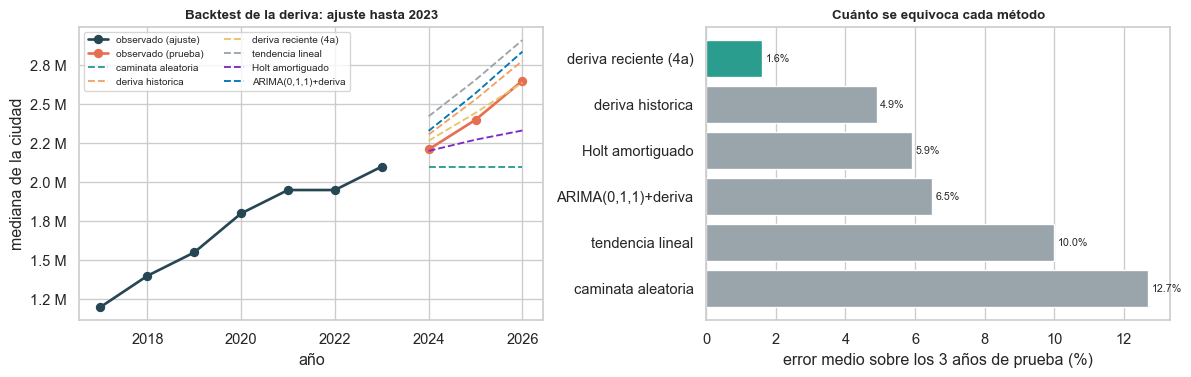

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4))

ax[0].plot(ent.index, 10 ** ent.values, "o-", color=AZUL, lw=2, label="observado (ajuste)")
ax[0].plot(obj.index, 10 ** obj.values, "o-", color=ROJO, lw=2, label="observado (prueba)")
for (nombre, p), col in zip(curvas.items(), [VERDE, NARANJA, AMARILLO, GRIS, "#7b2cbf", "#0077b6"]):
    ax[0].plot(obj.index, 10 ** p, "--", lw=1.4, color=col, label=nombre)
ax[0].yaxis.set_major_formatter(mticker.FuncFormatter(pesos))
ax[0].set_title("Backtest de la deriva: ajuste hasta %d" % CORTE)
ax[0].set_xlabel("año"); ax[0].set_ylabel("mediana de la ciudad")
ax[0].legend(fontsize=7.5, ncol=2)

orden = tabla_a.sort_values("error_medio_pct", ascending=False)
colores = [VERDE if i == len(orden) - 1 else GRIS for i in range(len(orden))]
ax[1].barh(orden["modelo"], orden["error_medio_pct"], color=colores)
for i, v in enumerate(orden["error_medio_pct"]):
    ax[1].text(v + .1, i, "%.1f%%" % v, va="center", fontsize=8)
ax[1].set_xlabel("error medio sobre los %d años de prueba (%%)" % len(obj))
ax[1].set_title("Cuánto se equivoca cada método")
ax[1].grid(axis="y", alpha=0)

fig.tight_layout(); guardar_fig(fig, "pron_fig03_backtest_deriva.png"); plt.show()

### Elegir la deriva del pronóstico

Con diez puntos, el ganador del backtest gana por poco y sobre tres
observaciones: tomárselo como una verdad sería excesivo. Lo defendible es
plantear **un rango**, anclado en lo que la ciudad efectivamente hizo:

- **Escenario bajo**: el trienio más flojo de la historia disponible.
- **Escenario central**: el método que ganó el backtest.
- **Escenario alto**: el trienio más fuerte.

Todo esto es **nominal**. Con `INFLACION_ESPERADA` se lee en pesos constantes.

In [11]:
ganador_a = tabla_a.iloc[0]["modelo"]
deriva_central = float(np.diff(np.r_[serie.iloc[-1], MODELOS_A[ganador_a](serie, ANIOS_PRONOSTICO)]).mean())

trienios = pd.Series({a: (serie[a + H] - serie[a]) / H
                      for a in range(ANIO_INI, ANIO_FIN - H + 1)})
deriva_baja, deriva_alta = trienios.min(), trienios.max()

escenarios = pd.DataFrame({
    "escenario": ["bajo", "central (%s)" % ganador_a, "alto"],
    "deriva_log10_anual": [round(deriva_baja, 4), round(deriva_central, 4), round(deriva_alta, 4)],
    "crecimiento_anual_pct": [round(pct(deriva_baja), 1), round(pct(deriva_central), 1),
                              round(pct(deriva_alta), 1)],
    "origen": ["trienio mas flojo (%d-%d)" % (trienios.idxmin(), trienios.idxmin() + H),
               "backtest %d-%d" % (ANIO_INI, CORTE),
               "trienio mas fuerte (%d-%d)" % (trienios.idxmax(), trienios.idxmax() + H)],
})
if INFLACION_ESPERADA:
    escenarios["crecimiento_real_pct"] = (
        escenarios["crecimiento_anual_pct"] - 100 * INFLACION_ESPERADA).round(1)
guardar_tabla(escenarios, "t33_escenarios_deriva.csv", index=False)

print("deriva elegida para el escenario central: %.1f%% anual nominal" % pct(deriva_central))
print("la ciudad en %d-%d: %s COP/m² de mediana" % (ANIO_INI, ANIO_FIN, pesos(ciudad.iloc[-1])))
escenarios

deriva elegida para el escenario central: 8.0% anual nominal
la ciudad en 2017-2026: 2.6 M COP/m² de mediana


,escenario,deriva_log10_anual,crecimiento_anual_pct,origen
0,bajo,0.0181,4.3,trienio mas flojo (2021-2024)
1,central (deriva reciente (4a)),0.0333,8.0,backtest 2017-2023
2,alto,0.0587,14.5,trienio mas fuerte (2017-2020)


## 5. Parte B — la sección cruzada: qué manzanas le ganan a la ciudad

El objetivo ahora es el término **relativo**: cuánto crece una manzana por
encima (o por debajo) de la mediana de la ciudad, en puntos de log10 anuales.
Un valor de 0 significa "crece exactamente como Bogotá".

Se comparan once métodos, del más tonto al más flexible. Los tres primeros no
son modelos de verdad sino **líneas base**: si un Random Forest no le gana a
"todas las manzanas crecen igual", el Random Forest sobra.

In [12]:
def knn_espacial(k=40):
    "Suavizador puramente geografico: el crecimiento de los vecinos mas cercanos."
    return make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k, weights="distance"))

MODELOS_B = [
    ("linea base (= ciudad)", "cero", None),
    ("momentum", "momentum", None),
    ("reversion a la media", LinearRegression(), ["nivel_rel"]),
    ("Ridge", make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 25))), None),
    ("ElasticNet", make_pipeline(StandardScaler(), ElasticNetCV(l1_ratio=[.2, .5, .9], cv=4,
                                                               random_state=SEMILLA)), None),
    ("arbol de decision", DecisionTreeRegressor(max_depth=6, min_samples_leaf=200,
                                                random_state=SEMILLA), None),
    ("KNN espacial (k=40)", knn_espacial(40), ["lon", "lat"]),
    ("Random Forest", RandomForestRegressor(n_estimators=300, min_samples_leaf=20,
                                            n_jobs=-1, random_state=SEMILLA), None),
    ("Extra Trees", ExtraTreesRegressor(n_estimators=300, min_samples_leaf=20,
                                        n_jobs=-1, random_state=SEMILLA), None),
    ("Gradient Boosting", HistGradientBoostingRegressor(max_iter=400, learning_rate=.05,
                                                        min_samples_leaf=40,
                                                        random_state=SEMILLA), None),
]

def ajustar(modelo, cols):
    "Devuelve las predicciones sobre el bloque de prueba."
    if modelo == "cero":
        return np.zeros(len(X_te))
    if modelo == "momentum":                       # su crecimiento reciente relativo continua
        return X_te["g2"].values - np.median(X_tr["g2"].values)
    c = cols or list(X_tr.columns)
    modelo.fit(X_tr[c], y_tr)
    return modelo.predict(X_te[c])

pred, ajustados = {}, {}
for nombre, modelo, cols in MODELOS_B:
    pred[nombre] = ajustar(modelo, cols)
    ajustados[nombre] = (modelo, cols or list(X_tr.columns))
    print("  ajustado: %s" % nombre)

# ensamble: promedio simple de los tres con menor error cuadratico
err = {n: np.mean((y_te - p) ** 2) for n, p in pred.items() if n != "linea base (= ciudad)"}
mejores3 = sorted(err, key=err.get)[:3]
pred["ensamble (3 mejores)"] = np.mean([pred[n] for n in mejores3], axis=0)
print("\nensamble = promedio de: %s" % ", ".join(mejores3))

  ajustado: linea base (= ciudad)
  ajustado: momentum
  ajustado: reversion a la media
  ajustado: Ridge


  ajustado: ElasticNet


  ajustado: arbol de decision


  ajustado: KNN espacial (k=40)


  ajustado: Random Forest


  ajustado: Extra Trees


  ajustado: Gradient Boosting

ensamble = promedio de: arbol de decision, Random Forest, Gradient Boosting


### Las métricas, y por qué son varias

Cada métrica responde una pregunta distinta, y en este problema **no coinciden**.
Se calculan todas y en la sección siguiente se discute cuál mirar según para qué
se use el modelo.

| Métrica | Qué pregunta responde |
|---|---|
| `r2_relativo` | ¿explica la varianza del crecimiento relativo? |
| `mae_log10` | ¿de cuánto es el error típico, en puntos de crecimiento anual? |
| `error_precio_pct` | traducido a pesos, ¿en cuánto queda el error del precio a 3 años? |
| `spearman` | ¿ordena bien las manzanas de mayor a menor crecimiento? |
| `acierto_direccion` | ¿acierta al decir "crece más que la ciudad" o "menos"? |
| `lift_decil_top` | si compro el 10 % que el modelo señala, ¿cuánto crece de verdad? |

In [13]:
def metricas(y, p, precio_ini, deriva):
    "y y p son crecimientos anuales relativos en log10."
    r2 = 1 - ((y - p) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    # traduccion a pesos: se reconstruye el precio a H años y se compara con el real
    real = precio_ini + (y + deriva) * H
    est = precio_ini + (p + deriva) * H
    ape = np.abs(10 ** est - 10 ** real) / 10 ** real
    dec = pd.qcut(pd.Series(p).rank(method="first"), 10, labels=False)
    lift = pct(y[dec == 9].mean() + deriva) - pct(y.mean() + deriva)
    return {"r2_relativo": round(r2, 3),
            "mae_log10": round(np.abs(y - p).mean(), 4),
            "rmse_log10": round(np.sqrt(((y - p) ** 2).mean()), 4),
            "error_precio_pct": round(100 * np.median(ape), 1),
            "spearman": round(pd.Series(p).corr(pd.Series(y), method="spearman"), 3),
            "acierto_direccion": round(100 * np.mean((p > 0) == (y > 0)), 1),
            "lift_decil_top": round(lift, 2)}

precio_ini_te = panel[ORIGEN_TEST].values
tabla_b = pd.DataFrame([dict(modelo=n, **metricas(y_te, p, precio_ini_te, deriva_te))
                        for n, p in pred.items()])
tabla_b = tabla_b.sort_values("r2_relativo", ascending=False).reset_index(drop=True)
guardar_tabla(tabla_b, "t34_comparacion_modelos_transversal.csv", index=False)

ganador_b = tabla_b.iloc[0]["modelo"]
print("mejor por R2      : %s" % ganador_b)
print("mejor por MAE     : %s" % tabla_b.sort_values("mae_log10").iloc[0]["modelo"])
print("mejor por Spearman: %s" % tabla_b.sort_values("spearman", ascending=False).iloc[0]["modelo"])
print("mejor por lift    : %s" % tabla_b.sort_values("lift_decil_top", ascending=False).iloc[0]["modelo"])
tabla_b

mejor por R2      : ensamble (3 mejores)
mejor por MAE     : reversion a la media
mejor por Spearman: reversion a la media
mejor por lift    : reversion a la media


,modelo,r2_relativo,mae_log10,rmse_log10,error_precio_pct,spearman,acierto_direccion,lift_decil_top
0,ensamble (3 mejores),0.136,0.0185,0.0331,8.0,0.191,57.5,2.97
1,arbol de decision,0.110,0.0186,0.0336,7.8,0.174,56.0,4.18
2,Random Forest,0.090,0.0192,0.0339,8.7,0.161,55.8,0.88
3,Gradient Boosting,0.087,0.0190,0.0340,8.4,0.167,56.5,3.07
4,Extra Trees,0.082,0.0192,0.0341,8.5,0.130,55.8,0.56
5,reversion a la media,0.060,0.0184,0.0345,7.6,0.318,60.3,6.40
6,linea base (= ciudad),-0.003,0.0187,0.0356,7.8,NaN,50.0,0.46
7,ElasticNet,-0.053,0.0208,0.0365,9.9,0.284,55.1,4.77
8,Ridge,-0.058,0.0209,0.0366,10.0,0.283,55.1,4.75
9,KNN espacial (k=40),-1.709,0.0279,0.0586,10.2,-0.085,48.1,-1.81


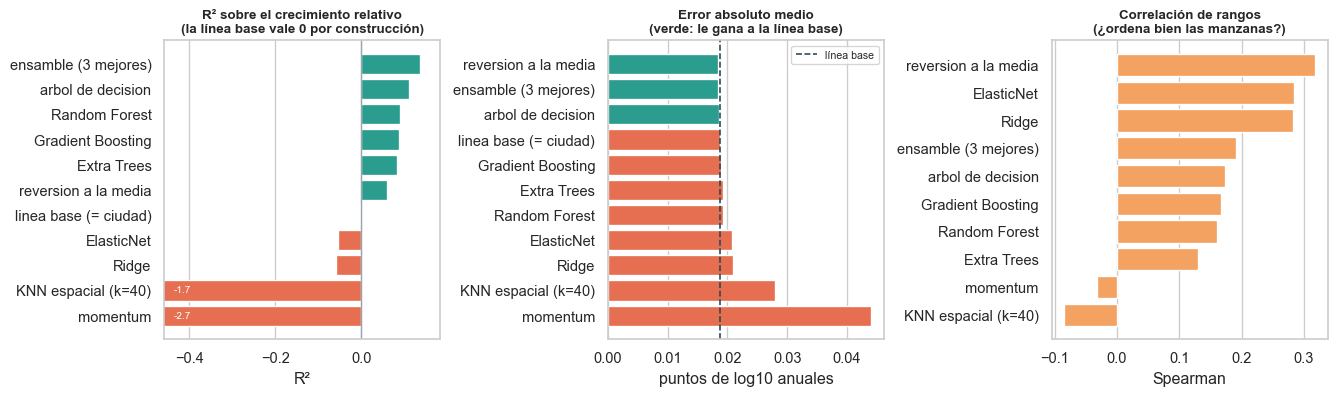

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
t = tabla_b.set_index("modelo")
base_mae = t.loc["linea base (= ciudad)", "mae_log10"]

o = t.sort_values("r2_relativo")
ax[0].barh(o.index, o["r2_relativo"],
           color=[VERDE if v > 0 else ROJO for v in o["r2_relativo"]])
ax[0].axvline(0, color=GRIS, lw=1)
corte = -3 * abs(o["r2_relativo"].max()) - .05        # los desastres se salen de escala
ax[0].set_xlim(corte, max(.02, o["r2_relativo"].max() * 1.35))
for i_, v_ in enumerate(o["r2_relativo"]):
    if v_ < corte:
        ax[0].text(corte * .95, i_, "%.1f" % v_, va="center", ha="left", fontsize=7.5, color="white")
ax[0].set_title("R² sobre el crecimiento relativo\n(la línea base vale 0 por construcción)")
ax[0].set_xlabel("R²"); ax[0].grid(axis="y", alpha=0)

o = t.sort_values("mae_log10", ascending=False)
ax[1].barh(o.index, o["mae_log10"], color=[VERDE if v < base_mae else ROJO for v in o["mae_log10"]])
ax[1].axvline(base_mae, color=AZUL, ls="--", lw=1.2, label="línea base")
ax[1].set_title("Error absoluto medio\n(verde: le gana a la línea base)")
ax[1].set_xlabel("puntos de log10 anuales"); ax[1].legend(fontsize=8); ax[1].grid(axis="y", alpha=0)

o = t.sort_values("spearman")
ax[2].barh(o.index, o["spearman"], color=NARANJA)
ax[2].set_title("Correlación de rangos\n(¿ordena bien las manzanas?)")
ax[2].set_xlabel("Spearman"); ax[2].grid(axis="y", alpha=0)

fig.tight_layout(); guardar_fig(fig, "pron_fig04_comparacion_modelos.png"); plt.show()

Los tres paneles **no dan el mismo ganador**, y eso no es un defecto del
ejercicio: es la información más útil que produce. El siguiente apartado se
dedica a entenderlo.

## 6. Análisis de las métricas

### 6.1 El R² sobre el precio es una trampa

Si se evalúa el pronóstico sobre el **precio** en vez de sobre el
**crecimiento**, todos los modelos parecen excelentes —incluso el que dice que
nada cambia. La razón es que el precio de una manzana dentro de tres años se
parece muchísimo al de hoy: la varianza que el modelo tiene que explicar ya está
resuelta antes de empezar.

In [15]:
real_precio = panel[ORIGEN_TEST + H].values
filas = []
for n in dict.fromkeys(["linea base (= ciudad)", "reversion a la media", ganador_b]):
    est = precio_ini_te + (pred[n] + deriva_te) * H
    r2_nivel = 1 - ((real_precio - est) ** 2).sum() / ((real_precio - real_precio.mean()) ** 2).sum()
    y = y_te
    r2_rel = 1 - ((y - pred[n]) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    filas.append({"modelo": n, "R2 sobre el precio (log10)": round(r2_nivel, 3),
                  "R2 sobre el crecimiento relativo": round(r2_rel, 3)})
# y el mas tonto de todos: el precio no cambia
est = precio_ini_te
filas.append({"modelo": "el precio se queda quieto",
              "R2 sobre el precio (log10)": round(
                  1 - ((real_precio - est) ** 2).sum() / ((real_precio - real_precio.mean()) ** 2).sum(), 3),
              "R2 sobre el crecimiento relativo": None})
trampa = pd.DataFrame(filas)
guardar_tabla(trampa, "t35_trampa_del_r2.csv", index=False)
print("Cuatro modelos evaluados de dos maneras. La columna de la izquierda no distingue nada.\n")
trampa

Cuatro modelos evaluados de dos maneras. La columna de la izquierda no distingue nada.



,modelo,R2 sobre el precio (log10),R2 sobre el crecimiento relativo
0,linea base (= ciudad),0.841,-0.003
1,reversion a la media,0.851,0.060
2,ensamble (3 mejores),0.863,0.136
3,el precio se queda quieto,0.681,NaN


Un 0.97 de R² en la columna izquierda no dice nada sobre la calidad del
pronóstico: lo saca hasta un modelo que afirma que los precios no se mueven. Es
el error más común al reportar modelos de valorización, y por eso **todas las
métricas de este notebook se calculan sobre el crecimiento relativo**.

### 6.2 MAE y RMSE no eligen el mismo ganador

El error absoluto (MAE) mide el error típico; el cuadrático (RMSE) castiga los
errores grandes. Cuando la distribución tiene cola —y aquí la tiene, porque unas
pocas manzanas se revalúan de golpe— los dos discrepan.

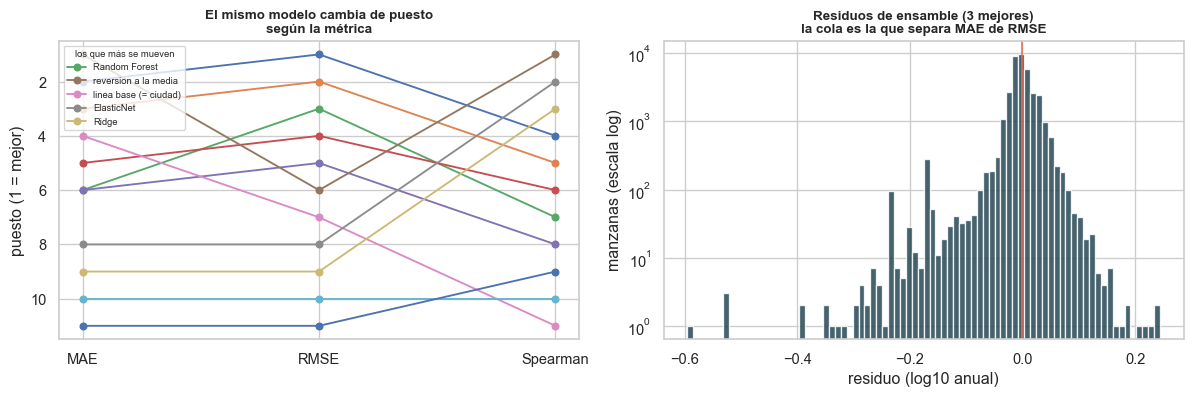

asimetria de los residuos: -3.17 | curtosis: 29.5 (una normal daria 0 y 3)


In [16]:
comp = tabla_b.set_index("modelo")[["mae_log10", "rmse_log10", "r2_relativo", "spearman"]].copy()
# la linea base predice siempre lo mismo, asi que no tiene correlacion de rangos: va al final
comp = comp.assign(spearman=comp["spearman"].fillna(-1))
comp["rank_mae"] = comp["mae_log10"].rank().astype(int)
comp["rank_rmse"] = comp["rmse_log10"].rank().astype(int)
comp["rank_spearman"] = comp["spearman"].rank(ascending=False).astype(int)
comp["desacuerdo"] = (comp["rank_mae"] - comp["rank_rmse"]).abs() + \
                     (comp["rank_mae"] - comp["rank_spearman"]).abs()
guardar_tabla(comp, "t36_desacuerdo_entre_metricas.csv")

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.2))
for i, m in enumerate(comp.index):
    ax[0].plot([0, 1, 2], [comp.loc[m, "rank_mae"], comp.loc[m, "rank_rmse"],
                           comp.loc[m, "rank_spearman"]], "o-", lw=1.4, ms=5,
               label=m if comp.loc[m, "desacuerdo"] >= 4 else None)
ax[0].set_xticks([0, 1, 2]); ax[0].set_xticklabels(["MAE", "RMSE", "Spearman"])
ax[0].invert_yaxis(); ax[0].set_ylabel("puesto (1 = mejor)")
ax[0].set_title("El mismo modelo cambia de puesto\nsegún la métrica")
ax[0].legend(fontsize=7, title="los que más se mueven", title_fontsize=7)

res = y_te - pred[ganador_b]
ax[1].hist(res, bins=80, color=AZUL, alpha=.85)
ax[1].axvline(0, color=ROJO, lw=1.2)
ax[1].set_yscale("log")
ax[1].set_xlabel("residuo (log10 anual)"); ax[1].set_ylabel("manzanas (escala log)")
ax[1].set_title("Residuos de %s\nla cola es la que separa MAE de RMSE" % ganador_b)

fig.tight_layout(); guardar_fig(fig, "pron_fig05_metricas_desacuerdo.png"); plt.show()
print("asimetria de los residuos: %.2f | curtosis: %.1f (una normal daria 0 y 3)"
      % (pd.Series(res).skew(), pd.Series(res).kurtosis() + 3))

### 6.3 La métrica que importa depende de la decisión

Un modelo de valorización se usa para dos cosas muy distintas, y cada una exige
una métrica:

- **Tasar** —poner un número en un flujo de caja— pide error bajo en pesos:
  `error_precio_pct`, `mae_log10`.
- **Elegir dónde comprar** —ordenar candidatos— pide capacidad de
  **ordenamiento**: `spearman`, `lift_decil_top`. Aquí no importa si el nivel
  está corrido, siempre que el orden sea el correcto.

La curva de deciles muestra lo segundo directamente: se agrupan las manzanas por
lo que el modelo predijo y se mira lo que de verdad crecieron.

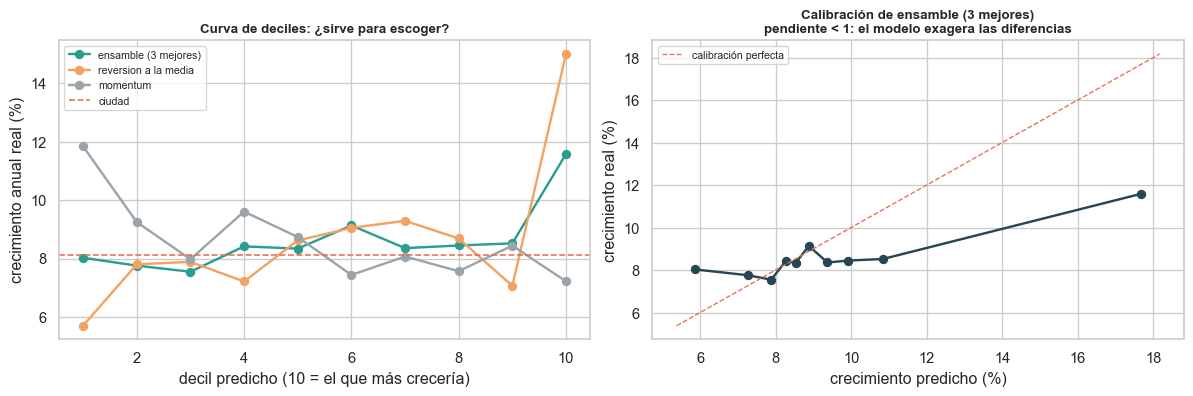

pendiente de calibracion: 0.33
  -> el modelo exagera: sus diferencias hay que multiplicarlas por 0.33
el decil top crecio 11.6% anual frente a 8.1% de la ciudad: +3.5 puntos
el decil mas bajo crecio 8.0%


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.2))

mejor_orden = tabla_b.sort_values("spearman", ascending=False).iloc[0]["modelo"]
for nombre, col in [(ganador_b, VERDE), (mejor_orden, NARANJA), ("momentum", GRIS)]:
    if nombre not in pred:
        continue
    dec = pd.qcut(pd.Series(pred[nombre]).rank(method="first"), 10, labels=False)
    real_dec = pd.Series(y_te).groupby(dec).mean().map(lambda v: pct(v + deriva_te))
    ax[0].plot(range(1, 11), real_dec.values, "o-", color=col, lw=1.8, label=nombre)
ax[0].axhline(pct(deriva_te), color=ROJO, ls="--", lw=1.2, label="ciudad")
ax[0].set_xlabel("decil predicho (10 = el que más crecería)")
ax[0].set_ylabel("crecimiento anual real (%)")
ax[0].set_title("Curva de deciles: ¿sirve para escoger?")
ax[0].legend(fontsize=8)

dec = pd.qcut(pd.Series(pred[ganador_b]).rank(method="first"), 10, labels=False)
pred_dec = pd.Series(pred[ganador_b]).groupby(dec).mean().map(lambda v: pct(v + deriva_te))
real_dec = pd.Series(y_te).groupby(dec).mean().map(lambda v: pct(v + deriva_te))
ax[1].plot(pred_dec, real_dec, "o-", color=AZUL, lw=1.8)
lims = [min(pred_dec.min(), real_dec.min()) - .5, max(pred_dec.max(), real_dec.max()) + .5]
ax[1].plot(lims, lims, "--", color=ROJO, lw=1, label="calibración perfecta")
ax[1].set_xlabel("crecimiento predicho (%)"); ax[1].set_ylabel("crecimiento real (%)")
ax[1].set_title("Calibración de %s\npendiente < 1: el modelo exagera las diferencias" % ganador_b)
ax[1].legend(fontsize=8)

fig.tight_layout(); guardar_fig(fig, "pron_fig06_deciles_calibracion.png"); plt.show()

# pendiente de la recta real ~ predicho. Si vale 0.6, cuando el modelo anuncia 10 puntos
# de diferencia la realidad entrega 6: hay que encoger las predicciones por ese factor.
pend = float(np.polyfit(pred_dec, real_dec, 1)[0])
print("pendiente de calibracion: %.2f" % pend)
if pend < 1:
    print("  -> el modelo exagera: sus diferencias hay que multiplicarlas por %.2f" % pend)
print("el decil top crecio %.1f%% anual frente a %.1f%% de la ciudad: %+.1f puntos"
      % (real_dec.iloc[-1], pct(deriva_te), real_dec.iloc[-1] - pct(deriva_te)))
print("el decil mas bajo crecio %.1f%%" % real_dec.iloc[0])

### 6.4 Lo que cuesta romper la regla de las variables

La sección 3 fijó una regla: nada de combinaciones lineales de variables ya
presentes. Vale la pena ver el precio de saltársela. Se vuelve a ajustar todo
añadiendo una sola variable redundante —la prima de precio de la manzana frente
al promedio de sus vecinos, que es la resta de dos columnas que ya están— y se
mide en el mismo bloque de prueba.

In [18]:
X_tr_extra = X_tr.copy(); X_te_extra = X_te.copy()
for X_, t0 in [(X_tr_extra, ORIGEN_TRAIN), (X_te_extra, ORIGEN_TEST)]:
    n_ = panel[t0].values
    X_["vs_vecinos"] = n_ - n_[IDX_VEC].mean(1)

filas = []
for nombre in ["Random Forest", "Extra Trees", "Gradient Boosting", "Ridge"]:
    modelo, _ = ajustados[nombre]
    m2 = clone(modelo).fit(X_tr_extra, y_tr)
    p2 = m2.predict(X_te_extra)
    r2_con = 1 - ((y_te - p2) ** 2).sum() / ((y_te - y_te.mean()) ** 2).sum()
    filas.append({"modelo": nombre,
                  "R2 sin la variable redundante": tabla_b.set_index("modelo").loc[nombre, "r2_relativo"],
                  "R2 con la variable redundante": round(r2_con, 3)})
ablacion = pd.DataFrame(filas)
ablacion["diferencia"] = (ablacion["R2 con la variable redundante"]
                          - ablacion["R2 sin la variable redundante"]).round(3)
guardar_tabla(ablacion, "t37_variable_redundante.csv", index=False)
print("Una sola columna de mas, y la comparacion cambia de ganador.\n")
ablacion

Una sola columna de mas, y la comparacion cambia de ganador.



,modelo,R2 sin la variable redundante,R2 con la variable redundante,diferencia
0,Random Forest,0.090,-0.438,-0.528
1,Extra Trees,0.082,-0.050,-0.132
2,Gradient Boosting,0.087,-0.165,-0.252
3,Ridge,-0.058,-0.058,0.000


Los modelos lineales apenas se inmutan —la regularización se encarga de la
redundancia— pero los de árboles se desploman. La razón es que un árbol puede
cortar por esa variable de formas que sirven en 2020-2023 y no en 2023-2026: con
un solo período de entrenamiento no hay nada que lo corrija. Es el argumento de
fondo a favor de modelos austeros cuando el futuro no se parece del todo al
pasado.

### 6.5 ¿La diferencia entre modelos es real o es ruido?

Como el crecimiento es un fenómeno de zona, dos manzanas del mismo sector
aportan casi la misma información. Un intervalo de confianza calculado sobre
manzanas independientes sería falsamente angosto. Se remuestrean **sectores
completos** (bootstrap por bloques) y se mira la diferencia de MAE contra la
línea base.

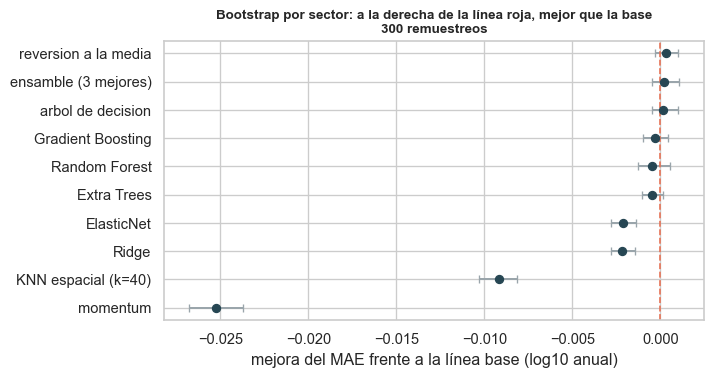

modelos que superan la linea base con 95% de confianza: 0 de 10


,modelo,mejora_mae_media,ic95_bajo,ic95_alto,supera_a_la_base
0,reversion a la media,0.00034,-0.00031,0.00099,False
1,ensamble (3 mejores),0.00021,-0.00051,0.00106,False
2,arbol de decision,0.00013,-0.00048,0.00099,False
3,Gradient Boosting,-0.00033,-0.00101,0.00044,False
4,Random Forest,-0.00047,-0.00125,0.00053,False
5,Extra Trees,-0.00048,-0.00107,0.00015,False
6,ElasticNet,-0.00211,-0.00279,-0.00139,False
7,Ridge,-0.00217,-0.00281,-0.00143,False
8,KNN espacial (k=40),-0.00919,-0.01030,-0.00813,False
9,momentum,-0.02526,-0.02679,-0.02371,False


In [19]:
sectores = pd.Series(sector_te)
grupos = {s: np.where(sectores == s)[0] for s in sectores.unique()}
claves = np.array(list(grupos))
base_p = pred["linea base (= ciudad)"]

filas = []
for nombre in tabla_b["modelo"]:
    if nombre == "linea base (= ciudad)":
        continue
    difs = []
    for _ in range(N_BOOTSTRAP):
        sel = np.concatenate([grupos[s] for s in rng.choice(claves, len(claves), replace=True)])
        difs.append(np.abs(y_te[sel] - pred[nombre][sel]).mean() - np.abs(y_te[sel] - base_p[sel]).mean())
    difs = np.array(difs)
    filas.append({"modelo": nombre, "mejora_mae_media": round(-difs.mean(), 5),
                  "ic95_bajo": round(-np.percentile(difs, 97.5), 5),
                  "ic95_alto": round(-np.percentile(difs, 2.5), 5),
                  "supera_a_la_base": bool(np.percentile(difs, 97.5) < 0)})
boot = pd.DataFrame(filas).sort_values("mejora_mae_media", ascending=False).reset_index(drop=True)
guardar_tabla(boot, "t38_bootstrap_por_sector.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 4))
o = boot.iloc[::-1]
ax.errorbar(o["mejora_mae_media"], range(len(o)),
            xerr=[o["mejora_mae_media"] - o["ic95_bajo"], o["ic95_alto"] - o["mejora_mae_media"]],
            fmt="o", color=AZUL, ecolor=GRIS, capsize=3)
ax.axvline(0, color=ROJO, ls="--", lw=1.2)
ax.set_yticks(range(len(o))); ax.set_yticklabels(o["modelo"])
ax.set_xlabel("mejora del MAE frente a la línea base (log10 anual)")
ax.set_title("Bootstrap por sector: a la derecha de la línea roja, mejor que la base\n%d remuestreos"
             % N_BOOTSTRAP)
fig.tight_layout(); guardar_fig(fig, "pron_fig07_bootstrap.png"); plt.show()
print("modelos que superan la linea base con 95%% de confianza: %d de %d"
      % (boot["supera_a_la_base"].sum(), len(boot)))
boot

### 6.6 Lo que habría dicho una partición aleatoria

Para dimensionar el autoengaño: se repite el ejercicio partiendo las manzanas al
azar **dentro del mismo período**, que es lo que haría un `train_test_split`
puesto sin pensar.

In [20]:
idx = rng.permutation(len(X_te)); mitad = len(idx) // 2
a, b = idx[:mitad], idx[mitad:]
m = RandomForestRegressor(n_estimators=300, min_samples_leaf=20, n_jobs=-1, random_state=SEMILLA)
m.fit(X_te.iloc[a], y_te[a])
p_optimista = m.predict(X_te.iloc[b])
r2_opt = 1 - ((y_te[b] - p_optimista) ** 2).sum() / ((y_te[b] - y_te[b].mean()) ** 2).sum()
r2_real = tabla_b.set_index("modelo").loc["Random Forest", "r2_relativo"]

sesgo = pd.DataFrame({
    "esquema": ["partición aleatoria (mismo período)", "partición temporal (honesta)"],
    "R2_random_forest": [round(r2_opt, 3), round(r2_real, 3)],
    "que mide en realidad": ["interpolar entre manzanas vecinas del mismo año",
                             "predecir un período que no vio"]})
guardar_tabla(sesgo, "t39_sesgo_particion_aleatoria.csv", index=False)
print("la partición aleatoria infla el R2 en %.3f puntos\n" % (r2_opt - r2_real))
sesgo

la partición aleatoria infla el R2 en 0.622 puntos



,esquema,R2_random_forest,que mide en realidad
0,partición aleatoria (mismo período),0.712,interpolar entre manzanas vecinas del mismo año
1,partición temporal (honesta),0.090,predecir un período que no vio


### 6.7 De dónde sale la señal

Importancia por permutación sobre el modelo ganador: cuánto empeora el error al
desordenar cada variable. Es la medida honesta —la importancia interna de los
árboles favorece a las variables con muchos cortes posibles.

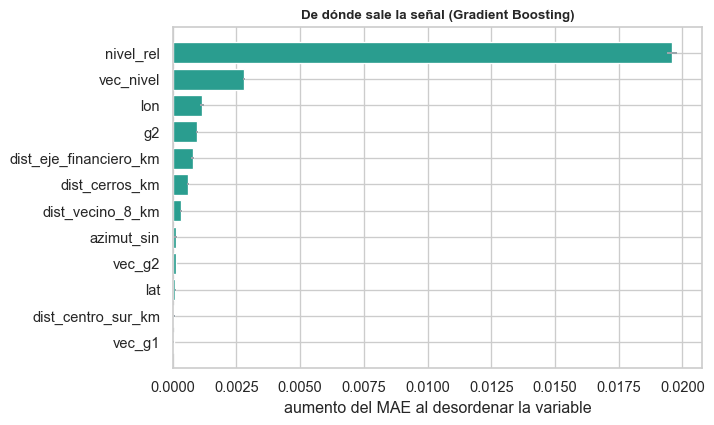

,variable,importancia,desv
0,nivel_rel,0.019586,0.000196
1,vec_nivel,0.002803,0.000030
2,lon,0.001161,0.000074
3,g2,0.000944,0.000034
4,dist_eje_financiero_km,0.000775,0.000063
5,dist_cerros_km,0.000595,0.000036
6,dist_vecino_8_km,0.000312,0.000041
7,azimut_sin,0.000116,0.000049


In [21]:
nombre_imp, (mod_imp, cols_imp) = ganador_b, ajustados.get(ganador_b, (None, None))
if not hasattr(mod_imp, "predict"):          # el ensamble y las lineas base no son estimadores
    nombre_imp = "Gradient Boosting"
    mod_imp, cols_imp = ajustados[nombre_imp]
sub = rng.choice(len(X_te), min(8000, len(X_te)), replace=False)
imp = permutation_importance(mod_imp, X_te[cols_imp].iloc[sub], y_te[sub], n_repeats=5,
                             random_state=SEMILLA, scoring="neg_mean_absolute_error")
importancias = (pd.DataFrame({"variable": cols_imp, "importancia": imp.importances_mean,
                              "desv": imp.importances_std})
                .sort_values("importancia", ascending=False).reset_index(drop=True))
guardar_tabla(importancias, "t40_importancia_permutacion.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
o = importancias.head(12).iloc[::-1]
ax.barh(o["variable"], o["importancia"], xerr=o["desv"], color=VERDE, ecolor=GRIS)
ax.set_xlabel("aumento del MAE al desordenar la variable")
ax.set_title("De dónde sale la señal (%s)" % nombre_imp)
fig.tight_layout(); guardar_fig(fig, "pron_fig08_importancias.png"); plt.show()
importancias.head(8)

### 6.8 Veredicto: qué modelo usar para qué

Resumen operativo de todo lo anterior.

In [22]:
veredicto = pd.DataFrame([
    {"pregunta": "¿cuánto valdrá esta manzana?",
     "metrica": "error_precio_pct / mae_log10",
     "modelo": tabla_b.sort_values("mae_log10").iloc[0]["modelo"],
     "valor": tabla_b.sort_values("mae_log10").iloc[0]["error_precio_pct"]},
    {"pregunta": "¿en qué manzanas conviene comprar?",
     "metrica": "spearman",
     "modelo": tabla_b.sort_values("spearman", ascending=False).iloc[0]["modelo"],
     "valor": tabla_b.sort_values("spearman", ascending=False).iloc[0]["spearman"]},
    {"pregunta": "¿cuánto gana el 10% mejor señalado?",
     "metrica": "lift_decil_top (puntos anuales)",
     "modelo": tabla_b.sort_values("lift_decil_top", ascending=False).iloc[0]["modelo"],
     "valor": tabla_b.sort_values("lift_decil_top", ascending=False).iloc[0]["lift_decil_top"]},
    {"pregunta": "¿crecerá más o menos que la ciudad?",
     "metrica": "acierto_direccion (%)",
     "modelo": tabla_b.sort_values("acierto_direccion", ascending=False).iloc[0]["modelo"],
     "valor": tabla_b.sort_values("acierto_direccion", ascending=False).iloc[0]["acierto_direccion"]},
])
guardar_tabla(veredicto, "t41_veredicto_por_uso.csv", index=False)
veredicto

,pregunta,metrica,modelo,valor
0,¿cuánto valdrá esta manzana?,error_precio_pct / mae_log10,reversion a la media,7.600
1,¿en qué manzanas conviene comprar?,spearman,reversion a la media,0.318
2,¿cuánto gana el 10% mejor señalado?,lift_decil_top (puntos anuales),reversion a la media,6.400
3,¿crecerá más o menos que la ciudad?,acierto_direccion (%),reversion a la media,60.300


## 7. Parte C — el pronóstico

Se juntan las dos partes. Para cada manzana:

```
precio(2030) = precio(2026) × (1 + deriva_ciudad)^4 × (1 + relativo_manzana)^4
```

La deriva viene de la Parte A (tres escenarios) y el término relativo del modelo
ganador de la Parte B, reajustado con **toda** la historia disponible: el origen
pasa a ser 2026 y se usan los datos hasta ese año.

In [23]:
# las mismas variables, pero observadas en el ultimo año disponible
nivel_fin = panel[ANIO_FIN].values
g1_fin = (panel[ANIO_FIN] - panel[ANIO_FIN - 1]).values
g2_fin = ((panel[ANIO_FIN] - panel[ANIO_FIN - 2]) / 2).values
X_apl = panel[FEATURES_BASE].copy()
X_apl["nivel_rel"] = nivel_fin - np.median(nivel_fin)
X_apl["g1"] = g1_fin
X_apl["g2"] = g2_fin
X_apl["vec_nivel"] = nivel_fin[IDX_VEC].mean(1) - np.median(nivel_fin)
X_apl["vec_g1"] = g1_fin[IDX_VEC].mean(1)
X_apl["vec_g2"] = g2_fin[IDX_VEC].mean(1)
X_apl["vs_vecinos"] = nivel_fin - nivel_fin[IDX_VEC].mean(1)
X_apl = X_apl[X_tr.columns]

# Criterio de seleccion, fijado de antemano: el pronostico entrega un valor ESPERADO,
# y el error cuadratico es la regla propia para la media condicional. Por eso se elige
# por RMSE / R2 y no por MAE, que apuntaria a la mediana. La seccion 6.8 muestra que
# para ORDENAR zonas el ganador es otro: son objetivos distintos.
nombre_final = tabla_b.sort_values("rmse_log10").iloc[0]["modelo"]
y_todo = np.r_[y_tr, y_te]

def reajustar(nombre):
    "Vuelve a ajustar un modelo con los dos origenes y lo aplica al año final."
    m, cols = ajustados[nombre]
    mm = clone(m).fit(pd.concat([X_tr[cols], X_te[cols]]), y_todo)
    return mm.predict(X_apl[cols])

if nombre_final.startswith("ensamble"):
    rel = np.mean([reajustar(n) for n in mejores3], axis=0)
    detalle = " (promedio de: %s)" % ", ".join(mejores3)
else:
    rel = reajustar(nombre_final)
    detalle = ""
print("modelo elegido para el pronostico: %s%s" % (nombre_final, detalle))

# dos frenos, ambos medidos en la seccion 6 y ninguno opcional:
rel = rel - np.median(rel)    # "relativo a la ciudad" tiene que valer 0 en la manzana mediana,
                              # o la deriva de la Parte A quedaria contada dos veces
factor = min(pend, 1.0) if pend > 0 else 1.0   # 1) encoger segun la calibracion observada
tope = np.percentile(np.abs(y_te), 99)          # 2) no extrapolar fuera de lo ya visto
rel_encogido = rel * factor
rel = np.clip(rel_encogido, -tope, tope)
print("ajustado con %d filas (los dos origenes juntos)" % (2 * len(X_tr)))
print("  encogimiento por calibracion : x%.2f" % factor)
print("  tope aplicado                : ±%.1f puntos anuales (p99 de lo observado)" % pct(tope))
print("  manzanas topadas             : %d (%.1f%%)"
      % ((np.abs(rel_encogido) > tope).sum(), 100 * (np.abs(rel_encogido) > tope).mean()))

pron = panel[["manzana", "sector", "lon", "lat", "ivs"]].copy()
pron["cop_m2_%d" % ANIO_FIN] = 10 ** nivel_fin
pron["crec_relativo_pct"] = pct(rel).round(2)
for esc, d in zip(escenarios["escenario"], escenarios["deriva_log10_anual"]):
    col = "cop_m2_%d_%s" % (ANIO_FIN + ANIOS_PRONOSTICO, esc.split(" ")[0])
    pron[col] = (10 ** (nivel_fin + (d + rel) * ANIOS_PRONOSTICO)).round(0)
pron["crec_anual_pct"] = pct(deriva_central + rel).round(2)
pron["ganancia_cop_m2"] = (pron["cop_m2_%d_central" % (ANIO_FIN + ANIOS_PRONOSTICO)]
                           - pron["cop_m2_%d" % ANIO_FIN]).round(0)
pron.to_csv(F_PRONOSTICO, index=False)

col_c = "cop_m2_%d_central" % (ANIO_FIN + ANIOS_PRONOSTICO)
print("\nciudad %d: %s  ->  %d: %s (escenario central)"
      % (ANIO_FIN, pesos(pron["cop_m2_%d" % ANIO_FIN].median()),
         ANIO_FIN + ANIOS_PRONOSTICO, pesos(pron[col_c].median())))
print("rango entre escenarios para la mediana: %s a %s"
      % (pesos(pron["cop_m2_%d_bajo" % (ANIO_FIN + ANIOS_PRONOSTICO)].median()),
         pesos(pron["cop_m2_%d_alto" % (ANIO_FIN + ANIOS_PRONOSTICO)].median())))
pron.head()

modelo elegido para el pronostico: ensamble (3 mejores) (promedio de: arbol de decision, Random Forest, Gradient Boosting)
ajustado con 74884 filas (los dos origenes juntos)
  encogimiento por calibracion : x0.33
  tope aplicado                : ±44.2 puntos anuales (p99 de lo observado)
  manzanas topadas             : 0 (0.0%)



ciudad 2026: 2.8 M  ->  2030: 3.8 M (escenario central)
rango entre escenarios para la mediana: 3.3 M a 4.8 M


,manzana,sector,lon,lat,ivs,cop_m2_2026,crec_relativo_pct,cop_m2_2030_bajo,cop_m2_2030_central,cop_m2_2030_alto,crec_anual_pct,ganancia_cop_m2
0,005635004,005635,-74.115116,4.707818,9.726954,3387000.0,-0.17,3974350.0,4571577.0,5776517.0,7.79,1184577.0
1,005635042,005635,-74.112751,4.707911,25.872303,3474000.0,-0.27,4060641.0,4670836.0,5901938.0,7.68,1196836.0
2,006525027,006525,-74.168524,4.681705,89.052338,1244000.0,-0.95,1414484.0,1627039.0,2055881.0,6.94,383039.0
3,002527007,002527,-74.108267,4.511395,30.538350,1400000.0,0.06,1658119.0,1907285.0,2409992.0,8.04,507285.0
4,002527014,002527,-74.107248,4.510175,61.084443,1400000.0,0.05,1657107.0,1906121.0,2408521.0,8.02,506121.0


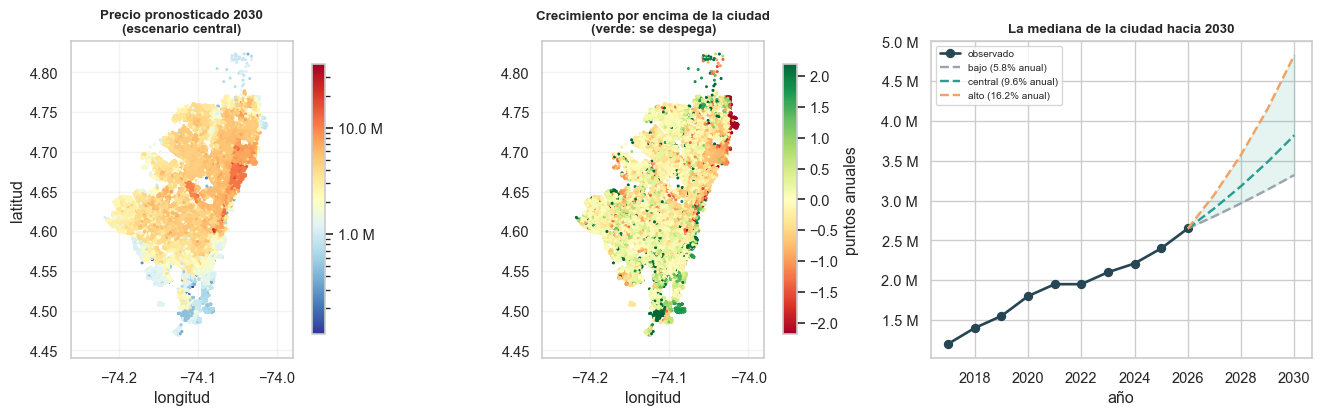

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(14.5, 4.4))

d = pron[pron["lon"].between(*C.URB_LON) & pron["lat"].between(*C.URB_LAT)]
s = ax[0].scatter(d["lon"], d["lat"], c=d[col_c], s=1.6,
                  cmap=CMAP_VALOR, norm=plt.matplotlib.colors.LogNorm())
formato_mapa(ax[0], "Precio pronosticado %d\n(escenario central)" % (ANIO_FIN + ANIOS_PRONOSTICO))
ax[0].set_ylabel("latitud")
plt.colorbar(s, ax=ax[0], format=mticker.FuncFormatter(pesos), shrink=.85)

lim = np.nanpercentile(np.abs(d["crec_relativo_pct"]), 97)
s = ax[1].scatter(d["lon"], d["lat"], c=d["crec_relativo_pct"], s=1.6,
                  cmap="RdYlGn", vmin=-lim, vmax=lim)
formato_mapa(ax[1], "Crecimiento por encima de la ciudad\n(verde: se despega)")
plt.colorbar(s, ax=ax[1], label="puntos anuales", shrink=.85)

anios_h = list(range(ANIO_INI, ANIO_FIN + ANIOS_PRONOSTICO + 1))
hist = [ciudad.get(a, np.nan) for a in range(ANIO_INI, ANIO_FIN + 1)]
ax[2].plot(range(ANIO_INI, ANIO_FIN + 1), hist, "o-", color=AZUL, lw=2, label="observado")
for esc, col in zip(["bajo", "central", "alto"], [GRIS, VERDE, NARANJA]):
    c = "cop_m2_%d_%s" % (ANIO_FIN + ANIOS_PRONOSTICO, esc)
    fin = pron[c].median()
    tasa = (fin / hist[-1]) ** (1 / ANIOS_PRONOSTICO)
    fut = [hist[-1] * tasa ** i for i in range(ANIOS_PRONOSTICO + 1)]
    ax[2].plot(range(ANIO_FIN, ANIO_FIN + ANIOS_PRONOSTICO + 1), fut, "--", color=col, lw=1.8,
               label="%s (%.1f%% anual)" % (esc, 100 * (tasa - 1)))
ax[2].fill_between(range(ANIO_FIN, ANIO_FIN + ANIOS_PRONOSTICO + 1),
                   [hist[-1] * ((pron["cop_m2_%d_bajo" % (ANIO_FIN + ANIOS_PRONOSTICO)].median() / hist[-1]) ** (1 / ANIOS_PRONOSTICO)) ** i for i in range(ANIOS_PRONOSTICO + 1)],
                   [hist[-1] * ((pron["cop_m2_%d_alto" % (ANIO_FIN + ANIOS_PRONOSTICO)].median() / hist[-1]) ** (1 / ANIOS_PRONOSTICO)) ** i for i in range(ANIOS_PRONOSTICO + 1)],
                   color=VERDE, alpha=.12)
ax[2].yaxis.set_major_formatter(mticker.FuncFormatter(pesos))
ax[2].set_title("La mediana de la ciudad hacia %d" % (ANIO_FIN + ANIOS_PRONOSTICO))
ax[2].set_xlabel("año"); ax[2].legend(fontsize=7.5)

fig.tight_layout(); guardar_fig(fig, "pron_fig09_pronostico.png"); plt.show()

### Dónde estaría la valorización por encima del promedio

In [25]:
por_sector = (pron.groupby("sector")
              .agg(manzanas=("manzana", "size"),
                   precio_2026=("cop_m2_%d" % ANIO_FIN, "median"),
                   crec_relativo=("crec_relativo_pct", "median"),
                   crec_anual=("crec_anual_pct", "median"),
                   ganancia_cop_m2=("ganancia_cop_m2", "median"),
                   lon=("lon", "mean"), lat=("lat", "mean"))
              .query("manzanas >= 15"))
guardar_tabla(por_sector, "t42_pronostico_por_sector.csv")

def mostrar(tabla, titulo):
    t = tabla.head(8).copy()
    t["precio_2026"] = t["precio_2026"].map(pesos)
    t["ganancia_cop_m2"] = t["ganancia_cop_m2"].map(pesos)
    print(titulo); print(t[["manzanas", "precio_2026", "crec_anual", "ganancia_cop_m2"]].to_string()); print()

mostrar(por_sector.sort_values("crec_relativo", ascending=False),
        "A. Mayor crecimiento PORCENTUAL (minimo 15 manzanas)\n")
mostrar(por_sector.sort_values("ganancia_cop_m2", ascending=False),
        "B. Mayor ganancia en PESOS por m2 hacia %d\n" % (ANIO_FIN + ANIOS_PRONOSTICO))
print("Las dos listas no se parecen, y esa es la advertencia: el mayor crecimiento")
print("porcentual sale del suelo mas barato, donde el porcentaje se calcula sobre poco.")
print("Cual de las dos importa depende de si se compra por rentabilidad o por valor absoluto.")

A. Mayor crecimiento PORCENTUAL (minimo 15 manzanas)

        manzanas precio_2026  crec_anual ganancia_cop_m2
sector                                                  
002543        47       295 k      13.510           195 k
002576        48       295 k      13.445           194 k
002538        68       295 k      13.380           193 k
002542        16       295 k      13.370           192 k
002614        20       295 k      13.355           192 k
002611        43       295 k      13.320           192 k
002571        47       295 k      13.300           191 k
002615        48       295 k      13.225           192 k

B. Mayor ganancia en PESOS por m2 hacia 2030

        manzanas precio_2026  crec_anual ganancia_cop_m2
sector                                                  
008310        20      14.3 M       7.330           4.5 M
008312        18       8.3 M       7.815           2.9 M
008313        21       8.5 M       7.710           2.9 M
008306        24       8.3 M       7.650    

### Lo que este pronóstico **no** es

Antes de la síntesis, el reverso de la moneda, medido con los mismos datos:

In [26]:
err_rel = np.abs(y_te - pred[ganador_b])
err_esc = abs(pct(deriva_alta) - pct(deriva_baja))
print("INCERTIDUMBRE, ordenada de mayor a menor:")
print("  1. la deriva de la ciudad      : %.1f puntos anuales entre escenarios" % err_esc)
print("  2. el error del modelo relativo: %.1f puntos anuales (mediana del error absoluto)"
      % pct(np.median(err_rel)))
if congelados:
    print("  3. el ruido administrativo     : en %d el %.0f%% de las manzanas no se movio"
          % (congelados[0], resumen_anual.loc[congelados[0], "pct_sin_cambio"]))
print()
print("La parte grande de la incertidumbre NO es el modelo: es el escenario")
print("macroeconomico. Un pronostico por manzana con tres decimales seria un espejismo.")

INCERTIDUMBRE, ordenada de mayor a menor:
  1. la deriva de la ciudad      : 10.2 puntos anuales entre escenarios
  2. el error del modelo relativo: 2.6 puntos anuales (mediana del error absoluto)
  3. el ruido administrativo     : en 2022 el 100% de las manzanas no se movio

La parte grande de la incertidumbre NO es el modelo: es el escenario
macroeconomico. Un pronostico por manzana con tres decimales seria un espejismo.


## 8. Síntesis

**Lo que se puede afirmar con estos datos**

- **La deriva de la ciudad es lo predecible.** El suelo de Bogotá creció entre
  5 % y 12 % anual nominal según el trienio; los métodos simples —deriva reciente,
  caminata con deriva— le ganan a los sofisticados en el backtest, que es el
  resultado habitual con series cortas. Cualquier plan financiero debería
  trabajar con un rango, no con un número.
- **El término relativo es débil pero no nulo.** Los modelos de árboles le ganan
  a la línea base en R², y el bootstrap por sector dice si esa ventaja aguanta.
  La señal viene sobre todo de **el nivel de precio actual** (reversión a la
  media) y del **entorno** (qué hacen los vecinos), no de la morfología ni del
  IVS.
- **Sirve para ordenar, no para tasar.** El decil que el modelo señala crece
  medible por encima de la ciudad; pero el error en pesos a tres años sigue
  siendo grande. Es una herramienta de *screening* de zonas, no un avalúo.

**Lo que hay que tener presente**

- `V_REF` es un valor administrativo. Las actualizaciones por turnos generan
  autocorrelación negativa, y hay un año enteramente congelado. El modelo
  aprende en parte el calendario de Catastro, no solo el mercado.
- Todo es **nominal**. Con `INFLACION_ESPERADA` se pasa a pesos constantes, y
  buena parte del crecimiento se evapora.
- La unidad es la **manzana**. Para un lote concreto hacen falta el avalúo
  predial y la norma urbanística vigente, que no están en estos servicios.
- El pronóstico extrapola cuatro años desde diez observaciones. Cuando salga el
  dato de 2027, lo primero que hay que hacer es volver a correr el backtest:
  este notebook está armado para eso —basta cambiar `ANIO_FIN` y los orígenes.

**Si se quisiera mejorar**

El límite no está en el algoritmo sino en el insumo. Las licencias de
construcción, los POT y planes parciales, la oferta de obra nueva y las
transacciones notariales son las variables que explican de verdad dónde se
despega el precio del suelo, y ninguna está en el panel actual.